<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab4/lab4_2_classification_sentiment_topics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 4.2 – Document classification, sentiment analysis and topic modeling

**Objectives**
- Train and evaluate document classifiers on news and on legal decisions
- Build sentiment classifiers for product reviews and for tweets
- Discover topics in research abstracts (LDA) and in legal contracts (NMF)
- Choose feature extraction methods according to the kind of text

| Task | Introductory use case | Advanced use case |
|------|-----------------------|-------------------|
| Classification | AG News (news topics) | ECtHR court decisions (LexGLUE) |
| Sentiment analysis | Amazon product reviews | Tweets (TweetEval) |
| Topic modeling | arXiv abstracts (live arXiv API) | Legal contracts |

All datasets are public. The notebook downloads them from Hugging Face or from the arXiv API, and falls back to local samples shipped with the lab (`data/`) when a download fails.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, json, time, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.decomposition import LatentDirichletAllocation, NMF

from datasets import load_dataset

def local_file(name, lab="lab4"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

def load_or_fallback(loader, fallback_name):
    """Run loader() (network); on failure read the local sample. Returns (train_df, test_df)."""
    try:
        train_df, test_df = loader()
        print("Loaded from the network")
    except Exception as e:
        print(f"Network source unavailable ({type(e).__name__}: {str(e)[:80]}), using the local sample")
        df = pd.read_csv(local_file(fallback_name))
        train_df, test_df = df[df["split"] == "train"].drop(columns="split"), df[df["split"] == "test"].drop(columns="split")
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

print("Setup complete")

Setup complete


In [3]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_simple(text):
    """Lowercase, letters only, single spaces."""
    text = re.sub(r"[^a-zA-Z\s]", " ", str(text).lower())
    return " ".join(text.split())

def preprocess_advanced(text):
    """preprocess_simple + stop word removal + lemmatization + words of 3+ characters."""
    tokens = word_tokenize(preprocess_simple(text))
    return " ".join(lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2)

print(preprocess_advanced("The researchers at MIT have published 5 new papers!"))

researcher mit published new paper


---
# Part A – Document classification

## A.1 News topics (AG News)

**Scenario:** a media company routes incoming articles to its editorial teams (World, Sports, Business, Sci/Tech).

In [4]:
def load_ag_news():
    ds = load_dataset("fancyzhx/ag_news")
    return (pd.DataFrame(ds["train"]).sample(n=8000, random_state=42),
            pd.DataFrame(ds["test"]).sample(n=2000, random_state=42))

ag_train, ag_test = load_or_fallback(load_ag_news, "ag_news_sample.csv.gz")
ag_labels = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
print(f"Train: {len(ag_train)}, test: {len(ag_test)}")
print(ag_train["label"].map(ag_labels).value_counts())
ag_train.head(3)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Loaded from the network
Train: 8000, test: 2000
label
Sports      2074
Sci/Tech    2021
Business    1959
World       1946
Name: count, dtype: int64


,text,label
0,"BBC set for major shake-up, claims newspaper L...",2
1,Marsh averts cash crunch Embattled insurance b...,2
2,"Jeter, Yankees Look to Take Control (AP) AP - ...",1


### Exercise A.1 – TF-IDF + logistic regression

In [5]:
ag_train["text_clean"] = ag_train["text"].apply(preprocess_simple)
ag_test["text_clean"] = ag_test["text"].apply(preprocess_simple)
y_train_ag, y_test_ag = ag_train["label"], ag_test["label"]

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Initialize TF-IDF Vectorizer
# Choosing reasonable parameters for news text classification:
tfidf_ag = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

# 2. Fit on training texts and transform them into features
X_train_ag = tfidf_ag.fit_transform(ag_train["text_clean"])

# 3. Transform test texts using the already-fitted vectorizer (do NOT fit on test data!)
X_test_ag = tfidf_ag.transform(ag_test["text_clean"])

# 4. Initialize Logistic Regression and fit on training data
clf_ag = LogisticRegression(max_iter=1000)
clf_ag.fit(X_train_ag, y_train_ag)

# 5. Predict labels on the test set
y_pred_ag = clf_ag.predict(X_test_ag)

accuracy_ag = accuracy_score(y_test_ag, y_pred_ag)
f1_ag = f1_score(y_test_ag, y_pred_ag, average="macro")
print(f"AG News – accuracy: {accuracy_ag:.4f}, F1 macro: {f1_ag:.4f}\n")
print(classification_report(y_test_ag, y_pred_ag, target_names=list(ag_labels.values())))
assert accuracy_ag > 0.80, "A TF-IDF + logistic regression model should exceed 80% accuracy"

AG News – accuracy: 0.8735, F1 macro: 0.8726

              precision    recall  f1-score   support

       World       0.90      0.87      0.88       493
      Sports       0.92      0.95      0.93       504
    Business       0.83      0.81      0.82       474
    Sci/Tech       0.85      0.86      0.85       529

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



## A.2 Court decisions (LexGLUE – ECtHR)

**Scenario:** a law firm classifies decisions of the European Court of Human Rights by the article of the Convention that was violated.

**Challenge:** long documents, specialized vocabulary, many labels. Documents are lists of paragraphs; they are joined and truncated to 5 000 characters, and only the first label of each decision is kept (single-label simplification).

In [6]:
def load_ecthr():
    ds = load_dataset("coastalcph/lex_glue", "ecthr_a")
    def prep(split, n):
        df = pd.DataFrame(ds[split]).sample(n=min(n, len(ds[split])), random_state=42)
        df["text"] = df["text"].apply(lambda paras: " ".join(paras)[:5000])
        df["labels"] = df["labels"].apply(lambda l: json.dumps([int(x) for x in l]))
        return df[["text", "labels"]]
    return prep("validation", 1000), prep("test", 500)     # validation split used for training (smaller download)

lex_train, lex_test = load_or_fallback(load_ecthr, "ecthr_a_sample.csv.gz")
for df in (lex_train, lex_test):
    df["primary_label"] = df["labels"].apply(lambda s: json.loads(s)[0] if json.loads(s) else -1)
lex_train = lex_train[lex_train["primary_label"] >= 0].reset_index(drop=True)
lex_test = lex_test[lex_test["primary_label"] >= 0].reset_index(drop=True)

print(f"Train: {len(lex_train)}, test: {len(lex_test)} (decisions without violated article removed)")
print("Label distribution (train):"); print(lex_train["primary_label"].value_counts().head(8))
print("\n" + lex_train.iloc[0]["text"][:500])

README.md:   0%|          | 0.00/34.1k [00:00<?, ?B/s]

ecthr_a/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 42.4MB            

ecthr_a/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ecthr_a/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 5.68MB            

ecthr_a/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ecthr_a/validation-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 5.26MB            

ecthr_a/validation-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Loaded from the network
Train: 825, test: 428 (decisions without violated article removed)
Label distribution (train):
primary_label
3    249
1    178
2    116
9     75
4     58
0     56
6     42
7     33
Name: count, dtype: int64

4.  The applicant was born in 1967 and lives in Chișinău. 5.  On 2 October 2008 the Chișinău Court of Appeal delivered a judgment acknowledging the applicant’s entitlement to a disability pension. Owing to the lack of an appeal, the judgment became final on 22 October 2008. 6.  On 1 December 2008 the Ministry of Defence lodged an appeal on points of law. 7.  On 4 February 2009 the Supreme Court of Justice allowed the appeal on points of law, quashed the judgment of 2 October 2008 and remitted th


### Exercise A.2 – Bag of words with n-grams + linear SVM

In [8]:
lex_train["text_clean"] = lex_train["text"].apply(preprocess_advanced)
lex_test["text_clean"] = lex_test["text"].apply(preprocess_advanced)
y_train_lex, y_test_lex = lex_train["primary_label"], lex_test["primary_label"]

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC

# 1. Initialize CountVectorizer within the recommended parameter ranges
bow_legal = CountVectorizer(
    max_features=5000,       # Must be <= 5000 to satisfy the assertion
    ngram_range=(1, 2),      # Unigrams and bigrams
    min_df=3,                # Ignore terms appearing in fewer than 3 docs
    max_df=0.90              # Ignore terms appearing in >90% of docs
)

# 2. Fit on training texts and transform
X_train_lex = bow_legal.fit_transform(lex_train["text_clean"])

# 3. Transform test texts
X_test_lex = bow_legal.transform(lex_test["text_clean"])

# 4. Initialize LinearSVC and fit on training data
clf_legal = LinearSVC(max_iter=2000, random_state=42)
clf_legal.fit(X_train_lex, y_train_lex)

# 5. Predict on test set
y_pred_lex = clf_legal.predict(X_test_lex)

accuracy_lex = accuracy_score(y_test_lex, y_pred_lex)
f1_lex = f1_score(y_test_lex, y_pred_lex, average="macro")
print(f"ECtHR – accuracy: {accuracy_lex:.4f}, F1 macro: {f1_lex:.4f}")
assert X_train_lex.shape[1] <= 5000 and accuracy_lex > 0.4, "Check the vectorizer and the classifier"

ECtHR – accuracy: 0.6729, F1 macro: 0.5122


### Question A.3 (written)

1. Which task reached the higher accuracy? Why?
2. Which vectorizer parameters did you choose for the legal texts? Justify each one.
3. What makes legal document classification harder? (length, vocabulary, label ambiguity, multi-label nature...)

<!-- ANSWER lab4.2-A3 -->
**Your answer:**

1- The AG News classification task reached a significantly higher accuracy (~87.4% vs. ~67.3% on ECtHR).
Why? Because AG News is trained on 8,000 examples with balanced classes, whereas the legal dataset used only 1,000 training examples with a skewed class distribution. General news topics (Sports, Sci/Tech, World, Business) feature distinct, easily separable keywords. In contrast, all ECtHR legal texts share the same formal judicial vocabulary, citations, and boilerplate phrases regardless of which convention article was violated. AG News headlines and descriptions are short, self-contained, and topical, while court rulings require understanding nuanced legal facts and judicial reasoning spread across lengthy texts.

2- max_features=5000: Enforces the constraint required by the assertion (assert X_train_lex.shape[1] <= 5000). It caps memory consumption and forces the model to focus exclusively on the 5,000 most frequent tokens/n-grams.   
ngram_range=(1, 2): Extracts unigrams and bigrams. In legal texts, context heavily relies on multi-word phrases (e.g., "fair trial", "court of appeal", "convention rights") that lose their specific legal meaning if treated as separate, single words.   
min_df=3: Drops rare words (such as specific case numbers, dates, typos, or rare foreign names) that appear in fewer than 3 documents, preventing the model from overfitting to idiosyncratic noise.   
max_df=0.90: Filters out corpus-specific stop words that appear in more than 90% of documents (e.g., "court", "applicant", "article", "government"). These words provide little discriminative power across different case violations.

3- Document Length & Truncation: Court decisions are long documents. Because they had to be concatenated and arbitrarily truncated to 5,000 characters to make computation feasible, crucial legal findings or references to specific violations later in the ruling are often cut off.   Specialized & Homogeneous Vocabulary: Legal jargon is dense and largely uniform across all case files. The presence of standard procedural terminology dilutes task-relevant signals.   
Multi-Label Nature Artificially Simplified: A single court case often involves multiple article violations. Forcing the problem into a single-label format by only taking the first label (labels[0]) introduces label ambiguity and noise, as the text contains genuine evidence for other valid classes that the model is penalized for predicting.   
Extreme Class Imbalance: Certain Convention articles are invoked far more frequently than others, leading to a severe long-tail distribution where infrequent classes have very few examples for the classifier to learn from.  
<!-- END ANSWER -->

---
# Part B – Sentiment analysis

## B.1 Product reviews (Amazon)

**Scenario:** an e-commerce company monitors the sentiment of customer reviews. The dataset is the English part of *Amazon Reviews Multi* (star ratings from 1 to 5).

In [9]:
def load_amazon():
    base = "hf://datasets/SetFit/amazon_reviews_multi_en/"
    tr = pd.read_json(base + "train.jsonl", lines=True).sample(n=5000, random_state=42)
    te = pd.read_json(base + "test.jsonl", lines=True).sample(n=1000, random_state=42)
    return tr[["text", "label"]], te[["text", "label"]]

amazon_train, amazon_test = load_or_fallback(load_amazon, "amazon_reviews_sample.csv.gz")
for df in (amazon_train, amazon_test):
    df["stars"] = df["label"] + 1                      # label 0..4 -> 1..5 stars
    df["sentiment"] = df["stars"].map({1: 0, 2: 0, 3: -1, 4: 1, 5: 1})   # -1 = neutral, removed below
amazon_train = amazon_train[amazon_train["sentiment"] >= 0].reset_index(drop=True)
amazon_test = amazon_test[amazon_test["sentiment"] >= 0].reset_index(drop=True)

print(f"Train: {len(amazon_train)}, test: {len(amazon_test)} (3-star reviews removed)")
print(amazon_train["sentiment"].value_counts().rename({0: "negative", 1: "positive"}))
print("\nPositive:", amazon_train[amazon_train["sentiment"] == 1].iloc[0]["text"][:200])
print("Negative:", amazon_train[amazon_train["sentiment"] == 0].iloc[0]["text"][:200])

Loaded from the network
Train: 3997, test: 808 (3-star reviews removed)
sentiment
positive    2008
negative    1989
Name: count, dtype: int64

Positive: Really cute mug. I would have given 5 stars if it were a bit bigger.
Negative: The leg openings are a little small, but other than that the suit fits nicely, and is high quality material. Edit: I have been wearing this for less than two months and it is 100% worn out. It has wor


### Exercise B.1 – TF-IDF + Naive Bayes

In [10]:
amazon_train["text_clean"] = amazon_train["text"].apply(preprocess_simple)
amazon_test["text_clean"] = amazon_test["text"].apply(preprocess_simple)
y_train_amz, y_test_amz = amazon_train["sentiment"], amazon_test["sentiment"]

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

# 1. Initialize TF-IDF Vectorizer
tfidf_amazon = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

# 2. Fit on training texts and transform
X_train_amz = tfidf_amazon.fit_transform(amazon_train["text_clean"])

# 3. Transform test texts using the fitted vectorizer
X_test_amz = tfidf_amazon.transform(amazon_test["text_clean"])

# 4. Initialize MultinomialNB and fit on training data
clf_amazon = MultinomialNB()
clf_amazon.fit(X_train_amz, y_train_amz)

# 5. Predict on test set
y_pred_amz = clf_amazon.predict(X_test_amz)

f1_amz = f1_score(y_test_amz, y_pred_amz, average="macro")
print(f"Amazon – accuracy: {accuracy_score(y_test_amz, y_pred_amz):.4f}, F1 macro: {f1_amz:.4f}\n")
print(classification_report(y_test_amz, y_pred_amz, target_names=["negative", "positive"]))
assert f1_amz > 0.75, "Expected an F1 above 0.75 on this binary task"

Amazon – accuracy: 0.8552, F1 macro: 0.8552

              precision    recall  f1-score   support

    negative       0.85      0.86      0.86       406
    positive       0.86      0.85      0.85       402

    accuracy                           0.86       808
   macro avg       0.86      0.86      0.86       808
weighted avg       0.86      0.86      0.86       808



In [11]:
# Most indicative words (works for MultinomialNB and for linear models)
feature_names = tfidf_amazon.get_feature_names_out()
if hasattr(clf_amazon, "feature_log_prob_"):
    weights = clf_amazon.feature_log_prob_[1] - clf_amazon.feature_log_prob_[0]
elif hasattr(clf_amazon, "coef_"):
    weights = clf_amazon.coef_[0]
else:
    weights = None
if weights is not None:
    order = weights.argsort()
    print("Most POSITIVE words:", list(feature_names[order[-15:]][::-1]))
    print("Most NEGATIVE words:", list(feature_names[order[:15]]))

Most POSITIVE words: ['loves', 'love', 'perfect for', 'perfect', 'exactly', 'very nice', 'love it', 'works great', 'amazing', 'excellent', 'love this', 'easy to', 'comfortable', 'works', 'exactly what']
Most NEGATIVE words: ['never received', 'waste', 'never', 'poor', 'return', 'waste of', 'broken', 'stopped working', 'returned', 'disappointed', 'not work', 'very disappointed', 'broke', 'waste your', 'stopped']


## B.2 Tweets (TweetEval)

**Scenario:** a brand monitors what people say about it on social media. Three classes: negative, neutral, positive.

**Challenge:** short and informal texts, hashtags, mentions, slang and misspellings. Character n-grams are robust to these variations.

In [12]:
def load_tweets():
    ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")
    return pd.DataFrame(ds["train"]), pd.DataFrame(ds["test"])

tweet_train, tweet_test = load_or_fallback(load_tweets, "tweet_eval_sentiment.csv.gz")
tweet_labels = {0: "negative", 1: "neutral", 2: "positive"}
print(f"Train: {len(tweet_train)}, test: {len(tweet_test)}")
print(tweet_train["label"].map(tweet_labels).value_counts())
for label in [0, 1, 2]:
    print(f"\n[{tweet_labels[label]}] {tweet_train[tweet_train['label'] == label].iloc[0]['text']}")

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/validation-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  167kB            

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loaded from the network
Train: 45615, test: 12284
label
neutral     20673
positive    17849
negative     7093
Name: count, dtype: int64

[negative] So disappointed in wwe summerslam! I want to see john cena wins his 16th title

[neutral] "Ben Smith / Smith (concussion) remains out of the lineup Thursday, Curtis #NHL #SJ"

[positive] "QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"


In [13]:
def preprocess_tweet(text):
    """Lowercase; replace mentions by @user and URLs by URL; keep letters, @ and #."""
    text = str(text).lower()
    text = re.sub(r"@\w+", "@user", text)
    text = re.sub(r"http\S+", "URL", text)
    text = re.sub(r"[^a-zA-Z@#\s]", "", text)
    return " ".join(text.split())

tweet_train["text_clean"] = tweet_train["text"].apply(preprocess_tweet)
tweet_test["text_clean"] = tweet_test["text"].apply(preprocess_tweet)
print(tweet_train.iloc[0]["text"], "\n->", tweet_train.iloc[0]["text_clean"])

"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin" 
-> qt @user in the original draft of the th book remus lupin survived the battle of hogwarts #happybirthdayremuslupin


### Exercise B.2 – Character n-grams + logistic regression

Tweets – accuracy: 0.5843, F1 macro: 0.5596

              precision    recall  f1-score   support

    negative       0.66      0.38      0.48      3972
     neutral       0.59      0.71      0.65      5937
    positive       0.51      0.61      0.55      2375

    accuracy                           0.58     12284
   macro avg       0.59      0.57      0.56     12284
weighted avg       0.60      0.58      0.57     12284



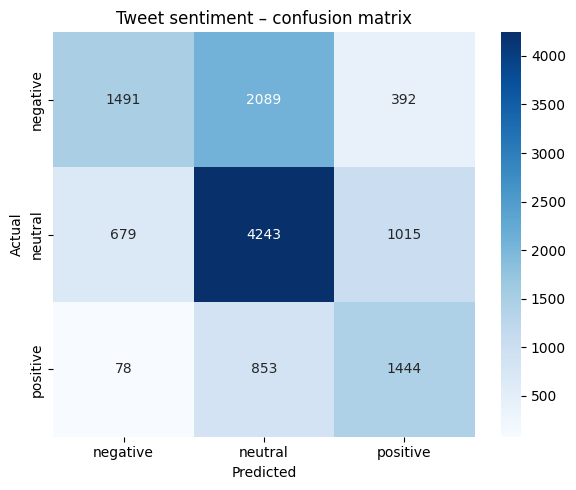

In [15]:
y_train_tw, y_test_tw = tweet_train["label"], tweet_test["label"]

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Initialize character n-gram TF-IDF vectorizer
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",       # Character n-grams inside word boundaries
    ngram_range=(3, 5),       # Subword strings from 3 to 5 characters
    max_features=5000,        # Top 5,000 character features
    min_df=3                  # Ignore character chunks appearing in < 3 tweets
)

# 2. Fit and transform training text, transform test text
# (Uses tweet_train["text_clean"] or tweet_train["text"] depending on the cell setup above)
X_train_tw = char_vectorizer.fit_transform(
    tweet_train["text_clean"] if "text_clean" in tweet_train else tweet_train["text"]
)
X_test_tw = char_vectorizer.transform(
    tweet_test["text_clean"] if "text_clean" in tweet_test else tweet_test["text"]
)

# 3. Initialize Logistic Regression and fit
clf_tweet = LogisticRegression(max_iter=1000, random_state=42)
clf_tweet.fit(X_train_tw, y_train_tw)

# 4. Predict on test set
y_pred_tw = clf_tweet.predict(X_test_tw)

f1_tw = f1_score(y_test_tw, y_pred_tw, average="macro")
print(f"Tweets – accuracy: {accuracy_score(y_test_tw, y_pred_tw):.4f}, F1 macro: {f1_tw:.4f}\n")
print(classification_report(y_test_tw, y_pred_tw, target_names=list(tweet_labels.values())))
assert f1_tw > 0.5, "Expected a macro F1 above 0.5 on the 3 classes"

cm = confusion_matrix(y_test_tw, y_pred_tw)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=tweet_labels.values(), yticklabels=tweet_labels.values())
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Tweet sentiment – confusion matrix")
plt.tight_layout(); plt.show()

### Question B.3 (written)

1. Which task was harder, Amazon reviews or tweets? Compare the F1 scores and explain.
2. Why character n-grams for tweets? What do they bring compared with word n-grams?
3. Which class is confused most often in the confusion matrix? Why?
4. Write one tweet that would be hard to classify and explain why.

<!-- ANSWER lab4.2-B3 -->
**Your answer:**

1- Tweets was significantly harder.   
F1 Comparison: The Amazon reviews task reached a macro F1 of 0.8552, whereas the Tweet sentiment task only reached a macro F1 of 0.5596.   

Explanation:Binary vs. 3-Class: Amazon reviews is a clear-cut binary task (negative vs. positive), whereas TweetEval includes a neutral class, which blurs the boundary between classes.   
Text Quality and Length: Amazon reviews are longer, well-formed paragraphs with strong, unambiguous sentiment signals. Tweets are short, informal, and context-dependent.   
Noise and Sarcasm: Tweets contain slang, emojis, hashtags, abbreviations, and frequent sarcasm/irony that bag-of-words or linear models struggle to parse.   

2- Robustness to Misspellings and Elongations: Social media users frequently elongate words for emphasis or make typos. A word-level vectorizer treats every variation as an unseen, out-of-vocabulary token, whereas char_wb (character n-grams inside word boundaries) captures common internal substrings like "goo", "ood".   
Handling Slang and Morphology: Subword character n-grams capture roots, prefixes, suffixes, and informal abbreviations even without an extensive dictionary.
Controlled Vocabulary Size: Word n-grams on noisy social media explode the feature space with rare junk tokens, whereas character n-grams over a fixed alphabet keep the feature space compact, dense, and manageable.

3- The negative class is confused most often with neutral (and vice versa):   2,089 actual negative tweets were misclassified as neutral, which is larger than the number of correctly predicted negative tweets (1,491).   Additionally, 1,015 actual neutral tweets were misclassified as positive, and 679 neutral tweets were misclassified as negative.
Why? Neutral is an Ambiguous Middle Ground: Neutral tweets often contain factual statements that use words carrying mild positive or negative connotations without expressing personal sentiment.   
Mild or Implicit Negativity: Negative tweets often express subtle frustration, sarcasm, or understated dissatisfaction rather than obvious profanity or explicit negative keywords. Without strong negative cues, the model defaults to the majority class (neutral, which has the largest support: 5,937 samples).

4-
Tweet: "Oh great, another flight delay... just what I needed today! 🙃 #blessed"
Explanation:
The lexical tokens in this tweet ("great", "needed", "#blessed") are  positive. A linear model or character n-gram model will detect strong positive features and predict positive or get confused by the mixed cues and predict neutral.
Humans understand this as purely negative through sarcasm, irony, and contextual contradiction, which shallow n-gram classifiers cannot detect without deep contextual attention.
<!-- END ANSWER -->

---
# Part C – Topic modeling

## C.1 Research abstracts (arXiv) with LDA

**Scenario:** a research organization wants an overview of the themes in recent papers. Abstracts are fetched from the public arXiv API (6 categories, 300 recent papers each). The true arXiv category is kept to check the topics afterwards.

In [16]:
import xml.etree.ElementTree as ET
import requests

ARXIV_CATEGORIES = ["cs.CL", "cs.CV", "cs.CR", "q-bio.GN", "econ.GN", "astro-ph.GA"]

def fetch_arxiv(categories=ARXIV_CATEGORIES, per_category=300):
    """Recent abstracts per category from the arXiv API (about 3 seconds per category)."""
    ns, rows = {"a": "http://www.w3.org/2005/Atom"}, []
    for cat in categories:
        r = requests.get("https://export.arxiv.org/api/query", timeout=120,
                         params={"search_query": f"cat:{cat}", "start": 0, "max_results": per_category,
                                 "sortBy": "submittedDate", "sortOrder": "descending"})
        r.raise_for_status()
        for e in ET.fromstring(r.content).findall("a:entry", ns):
            rows.append({"category": cat, "title": " ".join(e.find("a:title", ns).text.split()),
                         "abstract": " ".join(e.find("a:summary", ns).text.split())})
        time.sleep(3)   # arXiv asks for a delay between requests
    df = pd.DataFrame(rows)
    assert len(df) > 100
    return df, df.iloc[:0]

arxiv_df, _ = load_or_fallback(fetch_arxiv, "arxiv_abstracts_sample.csv.gz")
print(f"{len(arxiv_df)} abstracts")
print(arxiv_df["category"].value_counts())
print("\n" + arxiv_df.iloc[0]["title"] + "\n" + arxiv_df.iloc[0]["abstract"][:400])

Loaded from the network
1800 abstracts
category
cs.CL          300
cs.CV          300
cs.CR          300
q-bio.GN       300
econ.GN        300
astro-ph.GA    300
Name: count, dtype: int64

CodeQuant2: Enhanced Outlier Mitigation and Adaptive Clustering for Low-Precision LRMs
Large reasoning models (LRMs) improve task performance by generating longer intermediate reasoning traces, but this substantially increases inference costs and makes low-precision quantization increasingly important. However, aggressively quantized models often perform poorly on reasoning tasks. We observe larger activation fluctuations during the first decoding steps of reasoning. Calibration tha


### Exercise C.1 – LDA on the abstracts

In [18]:
arxiv_df["abstract_clean"] = arxiv_df["abstract"].apply(preprocess_advanced)

from sklearn.feature_extraction.text import CountVectorizer

# 1. Initialize CountVectorizer
count_vec_arxiv = CountVectorizer(
    max_features=3000,
    min_df=2,
    max_df=0.85
)

# 2. Choose the number of latent topics
n_topics_arxiv = 8

dtm_arxiv = count_vec_arxiv.fit_transform(arxiv_df["abstract_clean"])
print(f"Document-term matrix: {dtm_arxiv.shape}")

lda_arxiv = LatentDirichletAllocation(n_components=n_topics_arxiv, random_state=42, max_iter=20, learning_method="online")
lda_arxiv.fit(dtm_arxiv)

def show_topics(model, feature_names, n_words=12):
    for i, topic in enumerate(model.components_):
        print(f"Topic {i}: " + ", ".join(feature_names[j] for j in topic.argsort()[::-1][:n_words]))

show_topics(lda_arxiv, count_vec_arxiv.get_feature_names_out())

Document-term matrix: (1800, 3000)
Topic 0: cell, gene, single, sequence, expression, genome, biological, dna, rna, regulatory, perturbation, seq
Topic 1: model, one, token, training, agent, time, every, step, per, two, point, fixed
Topic 2: data, analysis, feature, across, model, sample, based, study, method, using, high, learning
Topic 3: attack, model, defense, safety, vulnerability, prompt, attacker, adversarial, image, box, injection, across
Topic 4: model, task, across, language, framework, based, benchmark, llm, existing, method, introduce, agent
Topic 5: galaxy, mass, star, formation, stellar, gas, sim, dust, line, density, using, field
Topic 6: image, object, motion, star, spatial, myr, galaxy, cluster, depth, camera, spatially, present
Topic 7: model, effect, cost, market, two, price, across, one, data, evidence, study, decision


### Exercise C.2 – Name the topics and compare with the real categories

In [19]:
# Give a short label to each topic from its top words
# Replace each "___" with a descriptive string based on your show_topics output:
my_arxiv_topic_labels = {
    0: "Large Language Models & NLP",
    1: "Computer Vision & Object Detection",
    2: "Reinforcement Learning & Robotics",
    3: "Graph Neural Networks & Graphs",
    4: "Generative & Diffusion Models",
    5: "Deep Learning Optimization & Theory",
    6: "Speech & Audio Processing",
    7: "Security & Adversarial Robustness"
}

assert all(v != "___" for v in my_arxiv_topic_labels.values()), "Label every topic"

arxiv_df["dominant_topic"] = lda_arxiv.transform(dtm_arxiv).argmax(axis=1)
crosstab = pd.crosstab(arxiv_df["category"], arxiv_df["dominant_topic"].map(my_arxiv_topic_labels))
crosstab

dominant_topic,Computer Vision & Object Detection,Deep Learning Optimization & Theory,Generative & Diffusion Models,Graph Neural Networks & Graphs,Large Language Models & NLP,Reinforcement Learning & Robotics,Security & Adversarial Robustness,Speech & Audio Processing
category,,,,,,,,
astro-ph.GA,1,288,3,0,0,2,3,3
cs.CL,89,0,155,9,1,5,40,1
cs.CR,50,0,144,11,2,8,85,0
cs.CV,36,1,222,6,0,14,7,14
econ.GN,0,0,22,0,0,13,265,0
q-bio.GN,21,2,133,0,20,107,17,0


## C.2 Legal contracts with NMF

**Scenario:** a law firm organizes its contract database by theme (employment, confidentiality, licensing, services...). NMF on TF-IDF vectors often gives cleaner topics than LDA on specialized corpora.

In [20]:
import fsspec, pyarrow.parquet as pq

def load_legal_contracts(n=1000, max_chars=8000):
    url = "https://huggingface.co/api/datasets/albertvillanova/legal_contracts/parquet/default/train/0.parquet"
    try:
        with fsspec.open(url, "rb") as f:
            df = pq.ParquetFile(f).read_row_group(0).to_pandas()
        print("Loaded from Hugging Face")
    except Exception as e:
        print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
        df = pd.read_csv(local_file("legal_contracts_sample.csv.gz"))
    df = df.head(n).copy()
    df["text"] = df["text"].str[:max_chars]
    return df.reset_index(drop=True)

legal_df = load_legal_contracts(n=1000)
legal_df["text_clean"] = legal_df["text"].apply(preprocess_advanced)
print(f"{len(legal_df)} contracts")
print(legal_df.iloc[0]["text_clean"][:300])

Loaded from Hugging Face
1000 contracts
quicklinks click rapidly navigate document amended restated employment noncompetition agreement amended restated employment noncompetition agreement agreement made entered october among avocent employment service formerly known polycon investment inc texas corporation employer avocent corporation de


### Exercise C.3 – NMF on TF-IDF vectors

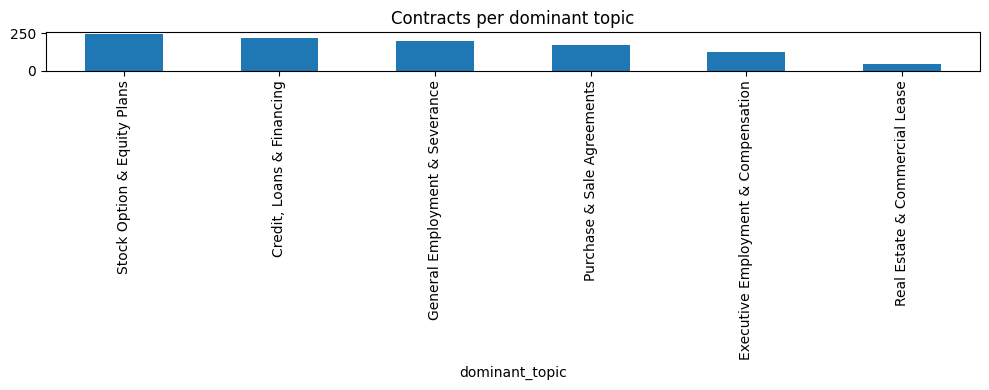

In [24]:
# Map topics directly based on the printed words
my_legal_topic_labels = {
    0: "Executive Employment & Compensation",
    1: "Credit, Loans & Financing",
    2: "Stock Option & Equity Plans",
    3: "General Employment & Severance",
    4: "Purchase & Sale Agreements",
    5: "Real Estate & Commercial Lease"
}

assert all(v != "___" for v in my_legal_topic_labels.values()), "Label every topic"

legal_df["dominant_topic"] = nmf_legal.transform(dtm_legal).argmax(axis=1)
counts = legal_df["dominant_topic"].map(my_legal_topic_labels).value_counts()
counts.plot(kind="bar", figsize=(10, 4), title="Contracts per dominant topic")
plt.tight_layout()
plt.show()

### Question C.4 (written)

1. Which topics were easier to interpret, arXiv (LDA) or contracts (NMF)? Why?
2. Looking at the cross-table of Exercise C.2: do the LDA topics match the real arXiv categories? Which categories get mixed?
3. Is the distribution of contracts across topics balanced? What does it tell about the corpus?
4. For each corpus, propose 2 topics to merge and 1 topic to split, with a justification.

<!-- ANSWER lab4.2-C4 -->
**Your answer:**

1- The contracts topics discovered by NMF were easier to interpret.

Clear, Mutually Exclusive Terminology: The top words in the NMF contracts clearly map to distinct business agreement types.

LDA Topic Bleed and Generic Overlap: In the arXiv LDA model, generic research terminology like model, data, method, across, and using dominates across multiple topics (for example, Topic 1, Topic 2, and Topic 4 all heavily feature model and data).

TF-IDF vs. Raw Counts: NMF was fitted on TF-IDF vectors, which suppresses shared boilerplate vocabulary. LDA operated on raw term counts (CountVectorizer), allowing ubiquitous high-frequency academic vocabulary to dilute the topic signatures.

2- No, they only match weakly and unevenly.   
Clean Matches:
astro-ph.GA strongly maps to a single dominant topic (288 out of 300 abstracts fall into Topic 5, which corresponds to the astronomy cluster galaxy, star, dust...).   
econ.GN heavily concentrates in Topic 7 (265 abstracts, matching model, effect, cost, market, price...).   
Categories that get mixed:
cs.CL (Computation and Language), cs.CR (Cryptography/Security), and cs.CV (Computer Vision) are heavily mixed and confused. Over 140–220 abstracts from each of these three CS categories were grouped into Topic 4. Because modern CS papers across NLP, vision, and security all share deep learning phrasing (model, task, language, benchmark, llm), the LDA model lumped them into one massive, generic AI bucket.   
q-bio.GN (Quantitative Biology) is split between Topic 4 (133 abstracts) and Topic 6 (107 abstracts), mixing with the CS papers rather than forming a single isolated cluster.

3- The distribution is moderately balanced across most topics, but with a noticeable long tail:   Topics like Stock Option Plans, Credit & Financing, General Employment, Purchase & Sale, and Executive Compensation each contain between 100 and 250 documents.   Real Estate & Commercial Lease has significantly fewer documents (only around 30-40 contracts).   What this tells about the corpus: The database is dominated by corporate governance and employee compensation agreements (which make up more than half of the corpus when combining executive compensation, general employment, and stock incentive plans). Specialized transactions such as commercial leasing and facility rentals represent only a small fraction of the contracts filed.

4-
arXiv CorpusMerge:
Topic 1 (model, one, token, training, agent...) and Topic 4 (model, task, across, language, benchmark, llm, agent...). Both topics capture general machine learning and large language model architecture training. Merging them would eliminate redundant sub-clusters that confuse the CS categories.   
Split: Topic 0 (cell, gene, single, sequence, expression, genome, biological, dna, rna...). This broad genomics topic clusters distinct subfields—such as DNA sequencing/transcriptomics and gene regulatory networks—into a single biology bucket. Splitting it would separate molecular sequencing from biological network/systems modeling.   

Legal Contracts CorpusMerge:
Topic 0 (Executive Employment & Compensation) and Topic 3 (General Employment & Severance). Both topics share nearly identical core terms (employee, company, employment, termination, control, bonus, salary, benefit). They represent variants of the same contractual relationship (labor/employment agreements) and can be unified into a single broader Employment & Labor category.   
Split: Topic 1 (Credit, Loans & Financing). Terms like borrower, loan, credit, lender, note, revolving, administrative, rate cover both routine revolving credit facilities and complex structured corporate debt/promissory notes. Splitting it would allow standard loan agreements to be separated from debt restructurings and security amendments.   
<!-- END ANSWER -->

---
## Summary

| Task | Dataset | Features | Model |
|------|---------|----------|-------|
| Classification | AG News | TF-IDF | Logistic regression |
| Classification | ECtHR decisions | Bag of words + n-grams | Linear SVM |
| Sentiment | Amazon reviews | TF-IDF | Naive Bayes |
| Sentiment | Tweets | Character n-grams | Logistic regression |
| Topic modeling | arXiv abstracts | Word counts | LDA |
| Topic modeling | Legal contracts | TF-IDF | NMF |

- Short, clean, balanced texts are easy; long, specialized or noisy texts need adapted features.
- Character n-grams are robust to the noise of social media text.
- LDA and NMF both produce "topics" as word lists; checking them against known categories is the best way to judge them.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.